In [5]:
import os
import pycorrelate as pyc

print('pycorrelate version:', pyc.__version__)

fname = r"D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\tttrmodeout.txt"

# Check if the file exists before trying to open it

with open(fname, 'r') as file:
    data = file.readlines()
    print(f"Successfully opened {fname}.")
    print(f"First 5 lines of the file:\n{''.join(data[:5])}")  # Show the first 5 lines



pycorrelate version: 0.3
Successfully opened D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\tttrmodeout.txt.
First 5 lines of the file:
ev chn time/ps

CH  1        1224334
CH  1        1733691
CH  1        2667403



In [20]:
import os
import numpy as np
import pycorrelate as pyc

print('pycorrelate version:', pyc.__version__)

fname = r"D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\tttrmodeout.txt"

# Lists to hold data for each channel
ch1_data = []
ch0_data = []  # Changed to handle CH 0 instead of CH 2

# Check if the file exists before trying to open it
if os.path.exists(fname):
    with open(fname, 'r') as file:
        # Skip the header line
        next(file)

        # Process each line in the file
        for line in file:
            parts = line.split()
            if len(parts) == 3:  # Ensure that the line has exactly 3 parts
                channel, _, time_ps = parts
                if channel == "CH":
                    if parts[1] == "1":
                        ch1_data.append(int(time_ps))
                    elif parts[1] == "0":  # Changed to CH 0
                        ch0_data.append(int(time_ps))

    # Check if both ch1_data and ch0_data are not empty
    if len(ch1_data) == 0 or len(ch0_data) == 0:
        print("Error: One or both of the channel data lists are empty.")
    else:
        # Convert lists to numpy arrays for pycorrelate
        ch1_array = np.array(ch1_data, dtype=np.int32)
        ch0_array = np.array(ch0_data, dtype=np.int32)

        # Now you can pass the numpy arrays to pycorrelate functions
        print(f"CH 1 data: {ch1_array[:5]}")  # Show first 5 values for CH 1
        print(f"CH 0 data: {ch0_array[:5]}")  # Show first 5 values for CH 0

        # Check the range of the data arrays
        if ch1_array.size > 0 and ch0_array.size > 0:
            data_min = min(ch1_array.min(), ch0_array.min())
            data_max = max(ch1_array.max(), ch0_array.max())

            if data_min == data_max:
                print("Warning: min and max values are equal. The data has no range, which may cause issues with bins and normalization.")
                # Handle the case where there's no variation in data (e.g., identical values)
                bins = np.array([0, 1])  # Use default bin edges if the data has no range
            else:
                bins = np.linspace(data_min, data_max, 101)  # 100 bins
                print(f"Bin edges: {bins[:5]}")  # Show first 5 bin edges

            # Now you can pass the numpy arrays and bins to pycorrelate
            try:
                correlation_result = pyc.pcorrelate(ch1_array, ch0_array, bins, normalize=True)
                print("Correlation result:", correlation_result)
            except ZeroDivisionError as e:
                print(f"Error during correlation: {e}")
                print("This could be due to a division by zero during normalization. Check the data range and try again.")
else:
    print(f"Error: The file {fname} does not exist.")


pycorrelate version: 0.3
CH 1 data: [1224334 1733691 2667403 3494006 3887072]
CH 0 data: [ 2904051  4319095  4901865  5530957 10433571]
Bin edges: [-2.14748240e+09 -2.10453279e+09 -2.06158317e+09 -2.01863355e+09
 -1.97568393e+09]
Error during correlation: division by zero
This could be due to a division by zero during normalization. Check the data range and try again.


In [16]:
print(ch1_array)
print(ch2_data)

[-2147478567 -2147474193 -2147467230 ...  2147465475  2147473083
  2147475022]
[]


Cross-correlation computed successfully!
[5.00000000e-03 0.00000000e+00 3.00000000e-03 1.00000000e-03
 0.00000000e+00 0.00000000e+00 7.38100000e+00 0.00000000e+00
 1.00000000e-03 3.00000000e-03 2.00000000e-03 1.00000000e-03
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 1.00000000e-03 0.00000000e+00 3.00000000e-03 0.00000000e+00
 1.00000000e-03 0.00000000e+00 2.00000000e-03 3.00000000e-03
 1.00000000e-03 1.00000000e-03 1.00000000e-03 0.00000000e+00
 0.00000000e+00 1.00000000e-03 2.00000000e-03 2.00000000e-03
 0.00000000e+00 0.00000000e+00 1.00000000e-03 0.00000000e+00
 3.92800000e+00 1.00000000e-03 0.00000000e+00 0.00000000e+00
 1.00000000e-03 1.00000000e-03 0.00000000e+00 2.00000000e-03
 0.00000000e+00 1.00000000e-03 1.00000000e-03 1.00000000e-03
 1.00000000e-03 1.00000000e-03 3.00000000e-03 2.00000000e-03
 0.00000000e+00 0.00000000e+00 2.00000000e-03 1.66814843e+06
 1.00000000e-03 1.00000000e-03 0.00000000e+00 0.00000000e+00
 0.00000000e+00 1.00000000e-03 2.00000000e-0

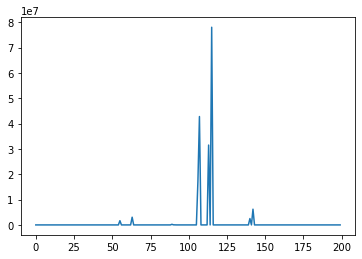

In [3]:
import numpy as np
import pycorrelate
import matplotlib.pyplot as plt

filename = r"D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\tttrmodeout.txt"  # Change this to your actual file path


times_ch0 = []
times_ch1 = []


with open(filename, "r") as file:
    for line in file:
        parts = line.strip().split()
        if len(parts) == 3 and parts[0] == "CH":
            channel = int(parts[1])
            time = int(parts[2])

            if channel == 0:
                times_ch0.append(time)
            elif channel == 1:
                times_ch1.append(time)

times_ch0 = np.array(times_ch0, dtype=np.float64)
times_ch1 = np.array(times_ch1, dtype=np.float64)


lags = np.arange(-100000, 100001, 1000)

correlation = pycorrelate.pcorrelate(times_ch0, times_ch1, lags)

print("Cross-correlation computed successfully!")
print(correlation)

plt.plot(correlation)


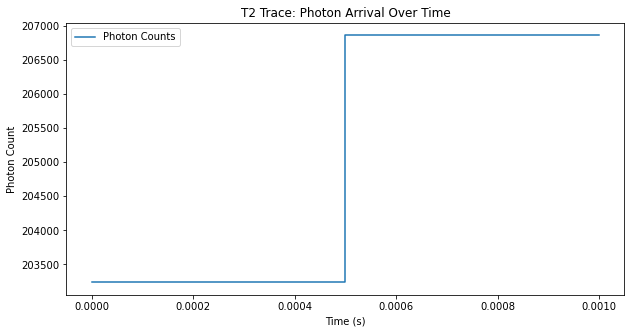

In [5]:
import numpy as np
import matplotlib.pyplot as plt


filename = r"D:\Experiments\Semiconductor Cavity\Pbec_Experimental_Code\tttrmodeout.txt"  # Change this to your actual file path

arrival_times = []

with open(filename, "r") as file:
    for line in file:
        parts = line.strip().split()
        if len(parts) == 3 and parts[0] == "CH":
            time = int(parts[2])
            arrival_times.append(time)


arrival_times = np.array(arrival_times, dtype=np.float64)

arrival_times_s = arrival_times * 1e-12

bin_width = 1e-3  # 1 ms bin size
bins = np.arange(0, np.max(arrival_times_s), bin_width)

photon_counts, _ = np.histogram(arrival_times_s, bins)


plt.figure(figsize=(10, 5))
plt.plot(bins[:-1], photon_counts, drawstyle="steps-mid", label="Photon Counts")
plt.xlabel("Time (s)")
plt.ylabel("Photon Count")
plt.title("T2 Trace: Photon Arrival Over Time")
plt.legend()
plt.show()
